<!-- m6:deber -->
# Módulo 6 · Deber — Detector bayesiano de fraude para PagoYa
**Diplomado en Big Data e Inteligencia Artificial · CEC-EPN** · Ing. Eduardo Avilés · individual · ≈ 3 horas

**Entrega:** Colab → **Archivo → Guardar (Ctrl+S)** → en *Repositorio* elija **el suyo** → ruta **`deber/deber.ipynb`** → mensaje `Deber`.
**Plazo: domingo 15-nov-2026, 11:00.** Un solo archivo: este cuaderno, ejecutado, con sus respuestas y el informe al final.

**Datos personalizados:** la API simulada genera transacciones **distintas para cada estudiante** a partir de su nombre. Sus cifras no coincidirán con las de sus compañeros; el docente puede regenerar sus datos para verificar.

| Parte | Tema | Puntos |
|---|---|---|
| 1 | Regresión logística bayesiana en PyMC (priors, muestreo y diagnóstico) | 20 |
| 2 | Comparación con boosting (XGBoost): discriminación y calibración | 20 |
| 3 | Modelo jerárquico por provincia | 20 |
| 4 | Decisión con matriz de costos e incertidumbre | 20 |
| 5 | Informe ejecutivo para el comité de riesgos | 20 |
| | **Total** | **100** |

**En cada parte:** código correcto y ejecutado (8) · resultados y diagnósticos (6) · interpretación propia (6).
Aquí no hay `___` para completar: el enunciado guía, **el código lo escribe usted** (puede reutilizar el de las clases 2 y 3).

## 0. Preparación

In [1]:
import importlib, subprocess, sys
for paquete in ['pymc']:
    if importlib.util.find_spec(paquete) is None:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', paquete])
import os, urllib.request, warnings, logging
URL = 'https://raw.githubusercontent.com/JavyAviles/m6-ia-plantilla/main/curso.py'
if not os.path.exists('curso.py'):
    urllib.request.urlretrieve(URL, 'curso.py')
import curso
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import pymc as pm
logging.getLogger('pymc').setLevel(logging.ERROR)
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, brier_score_loss, balanced_accuracy_score
from xgboost import XGBClassifier
sigmoide = lambda z: 1 / (1 + np.exp(-z))
print('Listo · curso', curso.VERSION)

Listo · curso m6-2026.11


**Escriba su nombre exactamente como en las clases ('Apellido Nombre').** Sus datos dependen de él.

In [2]:
NOMBRE = 'Benavides Coraima'                                               # ✏️ 'Apellido Nombre'
df = curso.datos_deber(NOMBRE)                               # datos personalizados + columna 'ratio'
df.head()

Huella de datos: Benavides Coraima · semilla 834912
Descargados 3006 eventos en 7 páginas de /v1/transacciones
Datos limpios: 2996 transacciones · tasa de fraude 9.51%


,evento_id,timestamp,id,edad,provincia,antiguedad_meses,ingreso_mensual,tipo,canal,categoria,monto,dispositivo_nuevo,distancia_km,intentos_pin,fraude,hora,ratio
0,TX-000000,2026-10-26 10:16:17-05:00,U0785,49.0,Imbabura,51,317.70,retiro_agente,app,efectivo,16.54,0,18.1,2,0,10,0.052062
1,TX-000001,2026-09-24 11:39:16-05:00,U0533,31.0,Tungurahua,58,998.06,pago_comercio,app,farmacia,125.39,0,1.3,3,0,11,0.125634
2,TX-000002,2026-09-06 19:12:55-05:00,U0463,56.0,Guayas,5,770.72,retiro_agente,app,efectivo,140.92,1,7.1,3,1,19,0.182842
3,TX-000003,2026-10-20 16:53:40-05:00,U0497,70.0,Guayas,8,1343.02,transferencia,app,persona,421.49,0,11.0,1,0,16,0.313837
4,TX-000004,2026-09-14 18:25:59-05:00,U0279,47.0,El Oro,54,1351.52,transferencia,app,persona,196.09,0,7.9,2,0,18,0.145088


In [3]:
# Partición FIJA (no la cambie): 70 % entrenamiento, 30 % prueba, estratificada
cols = ['dispositivo_nuevo', 'distancia_km', 'ratio', 'intentos_pin', 'hora']
X_train, X_test, y_train, y_test = train_test_split(df[cols], df['fraude'], test_size=0.3,
                                                    stratify=df['fraude'], random_state=42)
print('Entrenamiento:', X_train.shape, '· Prueba:', X_test.shape, '· tasa de fraude:', round(df['fraude'].mean(), 4))

Entrenamiento: (2097, 5) · Prueba: (899, 5) · tasa de fraude: 0.0951


---
## Parte 1 · Regresión logística bayesiana en PyMC (20 pts)
1. **Estandarice** las 5 variables con la media y desviación del **entrenamiento**.
2. Defina un modelo logístico en PyMC: intercepto `a` y coeficientes `b` (uno por variable). **Elija y justifique las priors** (en la celda de texto).
3. Muestree con **4 cadenas**, `tune=1000`, 1000 muestras y `random_seed=42`.
4. Muestre la tabla `curso.diagnostico(...)` y verifique **R-hat ≤ 1,01** y **ESS > 400** en todos los parámetros.
5. Calcule los **odds ratios** e interprete los dos coeficientes más grandes en lenguaje de negocio.
6. Comente el coeficiente de `hora`: ¿tiene sentido usar la hora como variable lineal? (pista: madrugada).

In [4]:
# ✏️ Escriba aquí su modelo (estandarización, priors, muestreo con 4 cadenas y tabla de diagnóstico)

# 1. Estandarización de variables
variables = X_train.columns.tolist()

media = X_train.mean()
desv = X_train.std(ddof=0).replace(0, 1)

X_train_std = ((X_train - media) / desv).to_numpy()
X_test_std = ((X_test - media) / desv).to_numpy()

# 2. Modelo bayesiano
with pm.Model() as modelo_bayes:

    # Distribuciones previas
    a = pm.Normal('a', mu=0, sigma=2.5)

    b = pm.Normal(
        'b',
        mu=0,
        sigma=1,
        shape=len(variables)
    )

    # Regresión logística
    logit_p = a + pm.math.dot(X_train_std, b)
    p = pm.math.sigmoid(logit_p)

    # Verosimilitud
    pm.Bernoulli(
        'y_obs',
        p=p,
        observed=np.asarray(y_train)
    )

    # Estimación MCMC
    tr_bayes = pm.sample(
        draws=1000,
        tune=1000,
        chains=4,
        random_seed=42,
        target_accept=0.95,
        progressbar=True
    )

# 3. Diagnóstico de convergencia
print("\nDIAGNÓSTICO DEL MODELO")

diagnostico = curso.diagnostico(
    tr_bayes,
    ['a', 'b']
)

display(diagnostico)

# 4. Resumen de parámetros
resumen = pm.summary(
    tr_bayes,
    var_names=['a', 'b']
)

print("\nRESUMEN DE PARÁMETROS")
display(resumen)

# 5. Coeficientes y odds ratios
coeficientes = (
    tr_bayes.posterior['b']
    .mean(dim=('chain', 'draw'))
    .values
)

tabla_or = pd.DataFrame({
    'Variable': variables,
    'Coeficiente': coeficientes,
    'Odds ratio': np.exp(coeficientes)
})

tabla_or['Magnitud'] = (
    tabla_or['Coeficiente'].abs()
)

tabla_or = tabla_or.sort_values(
    'Magnitud',
    ascending=False
)

print("\nCOEFICIENTES Y ODDS RATIOS")
display(
    tabla_or.drop(columns='Magnitud')
)

# 6. Dos coeficientes de mayor magnitud
print("\nDOS COEFICIENTES MÁS IMPORTANTES")
display(
    tabla_or.head(2).drop(columns='Magnitud')
)

# 7. Interpretación de la variable hora
print("\nVARIABLE HORA")
display(
    tabla_or.loc[
        tabla_or['Variable'] == 'hora'
    ].drop(columns='Magnitud')
)

# 8. Verificación final de convergencia
print("\nVERIFICACIÓN FINAL")

rhat_ok = (
    resumen['r_hat'] <= 1.01
).all()

ess_ok = (
    resumen['ess_bulk'] > 400
).all()

divergencias = int(
    tr_bayes.sample_stats['diverging'].sum()
)

print("R-hat <= 1.01:", rhat_ok)
print("ESS > 400:", ess_ok)
print("Divergencias:", divergencias)

if rhat_ok and ess_ok and divergencias == 0:
    print("CONVERGENCIA ADECUADA")
else:
    print("REVISAR DIAGNÓSTICOS DEL MODELO")

Output()


DIAGNÓSTICO DEL MODELO


,media,desv,ic_3%,ic_97%,r_hat,ess
a,-3.0975,0.1238,-3.3334,-2.8745,1.0012,2225.0144
b[0],0.9224,0.0652,0.8008,1.0450,1.0004,2565.4426
b[1],0.3331,0.0759,0.1932,0.4738,0.9997,4000.0000
b[2],0.7972,0.0745,0.6545,0.9413,0.9996,4000.0000
b[3],0.5614,0.0732,0.4270,0.7016,0.9998,3393.2173
b[4],-0.4206,0.0873,-0.5873,-0.2592,1.0011,4000.0000



RESUMEN DE PARÁMETROS


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
a,-3.098,0.124,-3.330,-2.873,0.003,0.002,2244.0,2963.0,1.0
b[0],0.922,0.065,0.805,1.049,0.001,0.001,2740.0,3392.0,1.0
b[1],0.333,0.076,0.196,0.474,0.001,0.001,4533.0,2801.0,1.0
b[2],0.797,0.074,0.666,0.950,0.001,0.001,3876.0,3189.0,1.0
b[3],0.561,0.073,0.422,0.697,0.001,0.001,3380.0,2880.0,1.0
b[4],-0.421,0.087,-0.582,-0.255,0.001,0.001,3610.0,3047.0,1.0



COEFICIENTES Y ODDS RATIOS


... (2 outputs left out)

,Variable,Coeficiente,Odds ratio
0,dispositivo_nuevo,0.922398,2.515314
2,ratio,0.797211,2.219344



VARIABLE HORA


,Variable,Coeficiente,Odds ratio
4,hora,-0.420572,0.656671



VERIFICACIÓN FINAL
R-hat <= 1.01: True
ESS > 400: True
Divergencias: 0
CONVERGENCIA ADECUADA


**✍️ Respuesta:**

Se estimó una regresión logística bayesiana con cuatro cadenas MCMC y variables estandarizadas a partir del entrenamiento. Se utilizaron distribuciones previas normales centradas en cero para regularizar los coeficientes sin imponer una dirección específica.

El modelo presentó una convergencia adecuada, con R-hat máximo de 1.0012, ESS superior a 2200 y cero divergencias.

Las variables con coeficientes de mayor magnitud fueron dispositivo_nuevo (OR = 2.52) y ratio (OR = 2.22). Esto indica que un dispositivo nuevo se asocia con odds de fraude aproximadamente 2.52 veces mayores, mientras que un aumento de una desviación estándar en ratio las multiplica por 2.22, manteniendo constantes las demás variables.

La variable hora presentó un coeficiente negativo (−0.421). Sin embargo, tratarla como lineal puede ser inadecuado porque las 23:00 y las 00:00 son horas consecutivas, aunque numéricamente estén muy separadas. Además, el riesgo durante la madrugada podría presentar un comportamiento diferente. Por ello, sería preferible utilizar una transformación cíclica de la hora o categorías horarias.

---
## Parte 2 · Comparación con boosting (20 pts)
1. Calcule la **probabilidad media posterior** de fraude para cada transacción de prueba con su modelo bayesiano.
2. Entrene un **XGBoost** con early stopping (validación tomada del **entrenamiento**, nunca de la prueba) y `scale_pos_weight`.
3. Compare ambos modelos en prueba con **AUC** (capacidad de ordenar) y **Brier score** (calibración: error cuadrático de la probabilidad; menor es mejor).
4. Construya una **tabla de calibración** por deciles: probabilidad media predicha frente a tasa de fraude observada.
5. Interprete: ¿cuál ordena mejor?, ¿cuál da probabilidades más confiables?, ¿por qué `scale_pos_weight` afecta la calibración?

Scale_pos_weight: 9.55
Mejor iteración XGBoost: 250

COMPARACIÓN DE MODELOS


,Modelo,AUC,Brier score
0,Bayesiano,0.8943,0.0550
1,XGBoost,0.9277,0.0616



TABLA DE CALIBRACIÓN POR DECILES


,decil,n,prob_media,fraude_observado,modelo
0,1,90,0.0076,0.0111,Bayesiano
1,2,90,0.0110,0.0111,Bayesiano
2,3,90,0.0145,0.0000,Bayesiano
3,4,90,0.0189,0.0222,Bayesiano
4,5,90,0.0245,0.0444,Bayesiano
5,6,89,0.0314,0.0112,Bayesiano
6,7,90,0.0474,0.0222,Bayesiano
7,8,90,0.0846,0.0778,Bayesiano
8,9,90,0.1758,0.1889,Bayesiano
9,10,90,0.4992,0.5667,Bayesiano


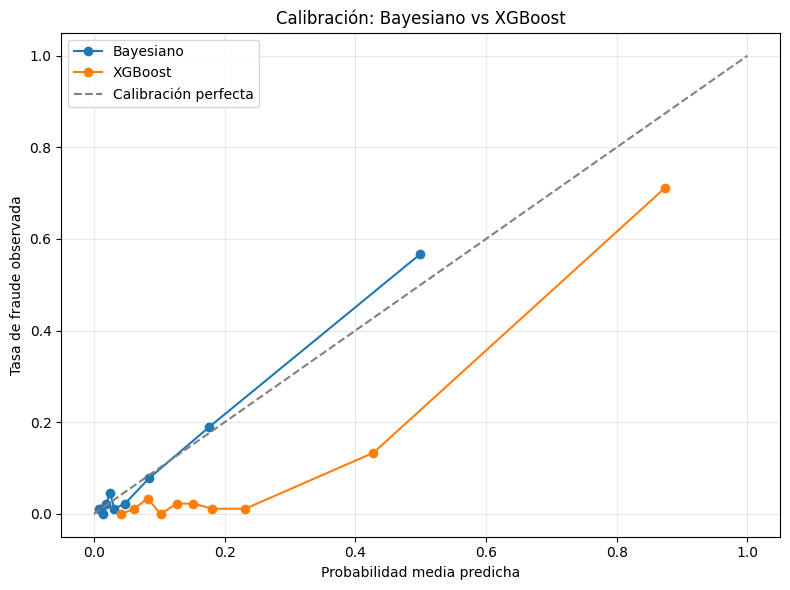


RESULTADOS FINALES
Mejor discriminación (AUC): XGBoost
Mejor Brier score: Bayesiano


In [5]:
# ✏️ Probabilidades del modelo bayesiano, XGBoost con early stopping, AUC, Brier y tabla de calibración

# 1. Probabilidades posteriores del modelo bayesiano
a_post = tr_bayes.posterior['a'].values.reshape(-1)
b_post = tr_bayes.posterior['b'].values.reshape(
    -1, len(variables)
)

logits = (
    a_post[:, None] +
    b_post @ X_test_std.T
)

prob_bayes = sigmoide(logits).mean(axis=0)

# 2. Validación interna para XGBoost
X_ent, X_val, y_ent, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    stratify=y_train,
    random_state=42
)

# Peso para compensar el desbalance
n_neg = (y_ent == 0).sum()
n_pos = (y_ent == 1).sum()
peso = n_neg / n_pos

print("Scale_pos_weight:", round(peso, 2))

# 3. Entrenamiento XGBoost con early stopping
modelo_xgb = XGBClassifier(
    n_estimators=1000,
    max_depth=3,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='binary:logistic',
    eval_metric='logloss',
    scale_pos_weight=peso,
    early_stopping_rounds=30,
    random_state=42,
    n_jobs=-1
)

modelo_xgb.fit(
    X_ent,
    y_ent,
    eval_set=[(X_val, y_val)],
    verbose=False
)

prob_xgb = modelo_xgb.predict_proba(X_test)[:, 1]

print("Mejor iteración XGBoost:",
      modelo_xgb.best_iteration)

# 4. Comparación de desempeño en prueba
resultados = pd.DataFrame({
    'Modelo': ['Bayesiano', 'XGBoost'],
    'AUC': [
        roc_auc_score(y_test, prob_bayes),
        roc_auc_score(y_test, prob_xgb)
    ],
    'Brier score': [
        brier_score_loss(y_test, prob_bayes),
        brier_score_loss(y_test, prob_xgb)
    ]
})

print("\nCOMPARACIÓN DE MODELOS")
display(resultados.round(4))

# 5. Función para calibración por deciles
def tabla_calibracion(prob, y, nombre):

    datos = pd.DataFrame({
        'probabilidad': np.asarray(prob),
        'fraude': np.asarray(y)
    })

    datos['decil'] = pd.qcut(
        datos['probabilidad'].rank(method='first'),
        q=10,
        labels=False
    ) + 1

    tabla = datos.groupby('decil').agg(
        n=('fraude', 'size'),
        prob_media=('probabilidad', 'mean'),
        fraude_observado=('fraude', 'mean')
    ).reset_index()

    tabla['modelo'] = nombre
    return tabla

cal_bayes = tabla_calibracion(
    prob_bayes, y_test, 'Bayesiano'
)

cal_xgb = tabla_calibracion(
    prob_xgb, y_test, 'XGBoost'
)

calibracion = pd.concat(
    [cal_bayes, cal_xgb],
    ignore_index=True
)

print("\nTABLA DE CALIBRACIÓN POR DECILES")
display(calibracion.round(4))

# 6. Gráfico de calibración
plt.figure(figsize=(8, 6))

for nombre, tabla in calibracion.groupby('modelo'):
    plt.plot(
        tabla['prob_media'],
        tabla['fraude_observado'],
        marker='o',
        label=nombre
    )

plt.plot(
    [0, 1], [0, 1],
    linestyle='--',
    color='gray',
    label='Calibración perfecta'
)

plt.xlabel('Probabilidad media predicha')
plt.ylabel('Tasa de fraude observada')
plt.title('Calibración: Bayesiano vs XGBoost')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 7. Comparación final
mejor_auc = resultados.loc[
    resultados['AUC'].idxmax(), 'Modelo'
]

mejor_brier = resultados.loc[
    resultados['Brier score'].idxmin(), 'Modelo'
]

print("\nRESULTADOS FINALES")
print("Mejor discriminación (AUC):", mejor_auc)
print("Mejor Brier score:", mejor_brier)

**✍️ Respuesta:**

XGBoost presentó una mayor capacidad de discriminación, con un AUC de 0.9277 frente a 0.8943 del modelo bayesiano. Sin embargo, este último obtuvo un menor Brier score (0.0550 frente a 0.0616), lo que indica una mayor precisión global de sus probabilidades estimadas.

El análisis por deciles muestra que XGBoost tiende a sobreestimar el riesgo de fraude, especialmente en el decil superior (87.37% estimado frente a 71.11% observado). Esto podría relacionarse con el uso de scale_pos_weight = 9.55 para compensar el desbalance de clases.

En conclusión, XGBoost es preferible para identificar y priorizar transacciones riesgosas, mientras que el modelo bayesiano resulta más adecuado para decisiones que requieren probabilidades bien calibradas. Como mejora, se podría evaluar una calibración posterior de XGBoost utilizando datos de validación.

---
## Parte 3 · Modelo jerárquico por provincia (20 pts)
1. Ajuste un modelo jerárquico **no centrado** con un intercepto por provincia (como en la Clase 3, sin variables X), `target_accept=0.99`, 4 cadenas.
2. Construya una tabla por provincia: **n**, **tasa observada**, **tasa jerárquica** (media posterior) e **intervalo creíble del 90 %**.
3. Reporte la media posterior de **sigma** e interprete.
4. ¿Qué provincias se «encogen» más hacia la media nacional y por qué?

Output()


DIAGNÓSTICO DEL MODELO


,media,desv,ic_3%,ic_97%,r_hat,ess
mu,-2.2698,0.1077,-2.4891,-2.0779,1.0003,1465.6099
sigma,0.1711,0.1397,0.0077,0.4824,1.0041,890.7344
z[0],-0.0027,0.8086,-1.5507,1.5457,1.0001,3869.6726
z[1],-0.5851,0.9105,-2.1984,1.2047,0.9997,3070.1799
z[2],0.3373,0.7538,-1.1428,1.7446,1.0002,2665.2574
z[3],0.1547,0.8804,-1.5044,1.7857,1.0019,4000.0000
z[4],0.0455,0.8545,-1.5839,1.6321,1.0000,4000.0000
z[5],-0.5823,0.8525,-2.1444,1.1911,0.9999,3028.7633
z[6],0.0143,0.7508,-1.4169,1.4628,1.0002,2535.1197
z[7],0.6462,0.9076,-1.1768,2.2353,1.0001,2895.7933



TASA NACIONAL: 9.51 %

RESULTADOS POR PROVINCIA


,n,tasa_observada,tasa_jerarquica,ic_5%,ic_95%,contraccion_pp
provincia,,,,,,
Azuay,289,0.0934,0.0942,0.0767,0.1122,0.0769
El Oro,195,0.0615,0.0849,0.0593,0.1048,2.3325
Guayas,925,0.1027,0.0990,0.0863,0.1141,0.3690
Imbabura,121,0.1074,0.0976,0.0761,0.1240,0.9862
Loja,187,0.0963,0.0950,0.0753,0.1160,0.1010
Manabí,294,0.0680,0.0851,0.0619,0.1034,1.7085
Pichincha,827,0.0943,0.0944,0.0810,0.1079,0.0069
Tungurahua,158,0.1392,0.1072,0.0855,0.1434,3.2027



SIGMA POSTERIOR: 0.1711

MAYOR CONTRACCIÓN HACIA LA MEDIA NACIONAL


,n,tasa_observada,tasa_jerarquica,ic_5%,ic_95%,contraccion_pp
provincia,,,,,,
Tungurahua,158,0.1392,0.1072,0.0855,0.1434,3.2027
El Oro,195,0.0615,0.0849,0.0593,0.1048,2.3325
Manabí,294,0.0680,0.0851,0.0619,0.1034,1.7085
Imbabura,121,0.1074,0.0976,0.0761,0.1240,0.9862
Guayas,925,0.1027,0.0990,0.0863,0.1141,0.3690


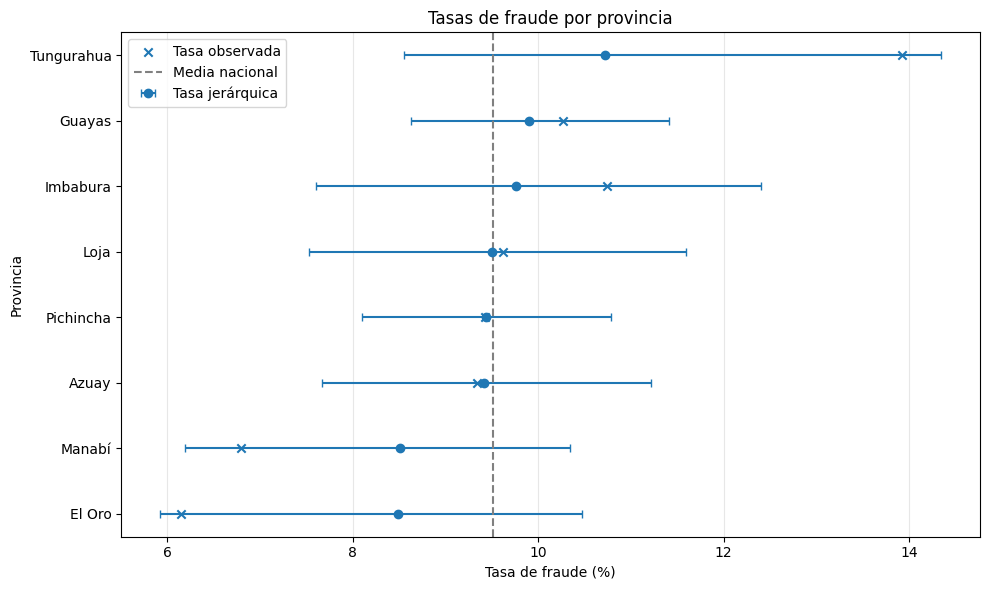


DIVERGENCIAS: 0
PROVINCIAS ANALIZADAS: 8


In [6]:
# ✏️ Modelo jerárquico no centrado, tabla por provincia e interpretación de sigma

# 1. Preparar datos por provincia
datos_prov = df[['provincia', 'fraude']].dropna().copy()

provincias = sorted(datos_prov['provincia'].unique())
codigos = pd.Categorical(
    datos_prov['provincia'],
    categories=provincias
).codes

n_provincias = len(provincias)
y_prov = datos_prov['fraude'].to_numpy()

# 2. Modelo jerárquico no centrado
with pm.Model() as modelo_jerarquico:

    # Intercepto global
    mu = pm.Normal('mu', mu=-3, sigma=2)

    # Variabilidad entre provincias
    sigma = pm.HalfNormal('sigma', sigma=1)

    # Parametrización no centrada
    z = pm.Normal(
        'z', mu=0, sigma=1,
        shape=n_provincias
    )

    alpha = pm.Deterministic(
        'alpha', mu + sigma * z
    )

    # Probabilidad de fraude por provincia
    p = pm.Deterministic(
        'p', pm.math.sigmoid(alpha)
    )

    pm.Bernoulli(
        'obs',
        p=p[codigos],
        observed=y_prov
    )

    tr_jer = pm.sample(
        draws=1000,
        tune=1000,
        chains=4,
        random_seed=42,
        target_accept=0.99,
        progressbar=True
    )

# 3. Diagnóstico de convergencia
print("\nDIAGNÓSTICO DEL MODELO")
display(
    curso.diagnostico(
        tr_jer, ['mu', 'sigma', 'z']
    )
)

# 4. Distribución posterior por provincia
p_post = tr_jer.posterior['p'].values.reshape(
    -1, n_provincias
)

# 5. Tabla de resultados
tabla_prov = (
    datos_prov.groupby('provincia')
    .agg(
        n=('fraude', 'size'),
        tasa_observada=('fraude', 'mean')
    )
    .reindex(provincias)
)

tabla_prov['tasa_jerarquica'] = p_post.mean(axis=0)

tabla_prov['ic_5%'] = np.percentile(
    p_post, 5, axis=0
)

tabla_prov['ic_95%'] = np.percentile(
    p_post, 95, axis=0
)

# 6. Media nacional
tasa_nacional = datos_prov['fraude'].mean()

tabla_prov['contraccion_pp'] = (
    abs(tabla_prov['tasa_observada'] - tasa_nacional)
    - abs(tabla_prov['tasa_jerarquica'] - tasa_nacional)
) * 100

print("\nTASA NACIONAL:", round(tasa_nacional * 100, 2), "%")

print("\nRESULTADOS POR PROVINCIA")
display(tabla_prov.round(4))

# 7. Sigma posterior
sigma_media = float(
    tr_jer.posterior['sigma'].mean()
)

print("\nSIGMA POSTERIOR:", round(sigma_media, 4))

# 8. Provincias con mayor contracción
print("\nMAYOR CONTRACCIÓN HACIA LA MEDIA NACIONAL")

display(
    tabla_prov.sort_values(
        'contraccion_pp',
        ascending=False
    ).head(5).round(4)
)

# 9. Gráfico de tasas provinciales
tabla_graf = tabla_prov.sort_values(
    'tasa_jerarquica'
)

plt.figure(figsize=(10, 6))

plt.errorbar(
    tabla_graf['tasa_jerarquica'] * 100,
    tabla_graf.index,
    xerr=[
        (tabla_graf['tasa_jerarquica']
         - tabla_graf['ic_5%']) * 100,
        (tabla_graf['ic_95%']
         - tabla_graf['tasa_jerarquica']) * 100
    ],
    fmt='o',
    capsize=3,
    label='Tasa jerárquica'
)

plt.scatter(
    tabla_graf['tasa_observada'] * 100,
    tabla_graf.index,
    marker='x',
    label='Tasa observada'
)

plt.axvline(
    tasa_nacional * 100,
    linestyle='--',
    color='gray',
    label='Media nacional'
)

plt.xlabel('Tasa de fraude (%)')
plt.ylabel('Provincia')
plt.title('Tasas de fraude por provincia')
plt.legend()
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

# 10. Verificación final
divergencias = int(
    tr_jer.sample_stats['diverging'].sum()
)

print("\nDIVERGENCIAS:", divergencias)
print("PROVINCIAS ANALIZADAS:", n_provincias)

**✍️ Respuesta:** Se estimó un modelo bayesiano jerárquico no centrado para ocho provincias, obteniendo tasas de fraude e intervalos creíbles del 90%. Los diagnósticos fueron adecuados, con R-hat máximo de 10041, ESS mínimo de 891 y cero divergencias.

La tasa nacional observada fue del 9.51% y el parámetro de heterogeneidad provincial presentó una media posterior de 0.1711 en escala logit.

El modelo evidencia un efecto de contracción hacia el nivel general. Tungurahua presentó el mayor ajuste, pasando del 13.92% observado al 10.72% estimado. También destacan El Oro (6.15% a 8.49%) y Manabí (6.80% a 8.51%).

Esta contracción permite moderar estimaciones extremas, especialmente cuando existe menor información provincial. No obstante, los intervalos creíbles muestran incertidumbre considerable y se superponen entre provincias, por lo que no sería adecuado afirmar que sus riesgos son significativamente diferentes únicamente a partir de las tasas puntuales.

---
## Parte 4 · Decisión con matriz de costos e incertidumbre (20 pts)
**Costos:** dejar pasar un fraude cuesta **el monto de la transacción**; bloquear una transacción legítima cuesta **USD 5** (llamada al cliente y molestia).
1. Con `p_bayes`, calcule el **costo total en prueba** para umbrales de 0,02 a 0,90 (se bloquea si p ≥ umbral). Grafique costo frente a umbral y elija el **umbral óptimo**.
2. Compare con dos políticas extremas: **no bloquear nada** y **bloquear todo**.
3. **Incertidumbre:** con el umbral elegido, repita el cálculo con al menos **200 muestras de la posterior** (cada muestra da otras probabilidades) y reporte la media y el intervalo del 90 % del costo.
4. *(Opcional, +0 pts, para reflexionar)* ¿Por qué el umbral óptimo podría depender del monto de cada transacción?

UMBRAL OPTIMO: 0.07
COSTO MINIMO (USD): 1555.92

COMPARACION DE POLITICAS


,Politica,Costo USD
0,No bloquear nada,13454.94
1,Bloquear todo,4065.00
2,Umbral optimo,1555.92



AHORRO FRENTE A NO BLOQUEAR
USD: 11899.02


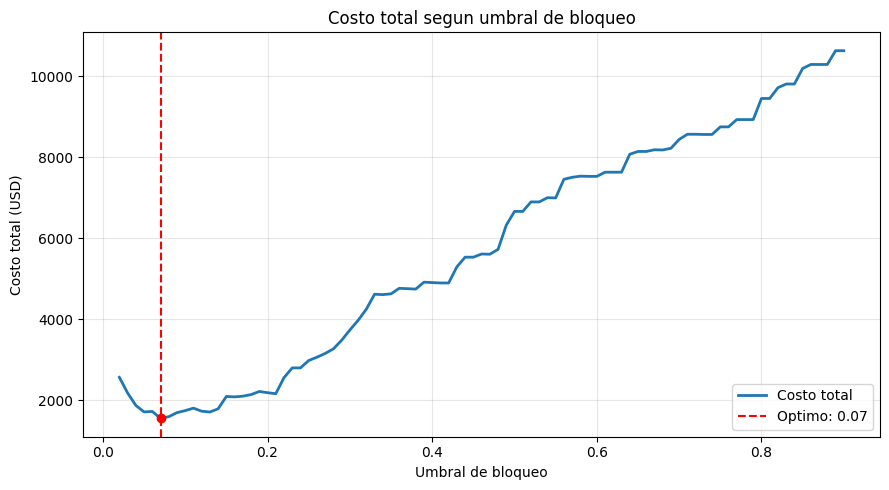


RESULTADOS CON INCERTIDUMBRE


,Indicador,Valor
0,Umbral optimo,0.07
1,Costo con probabilidad media,1555.92
2,Costo medio posterior,1640.02
3,Limite inferior 90%,1520.61
4,Limite superior 90%,1791.31
5,Ahorro frente a no bloquear,11899.02


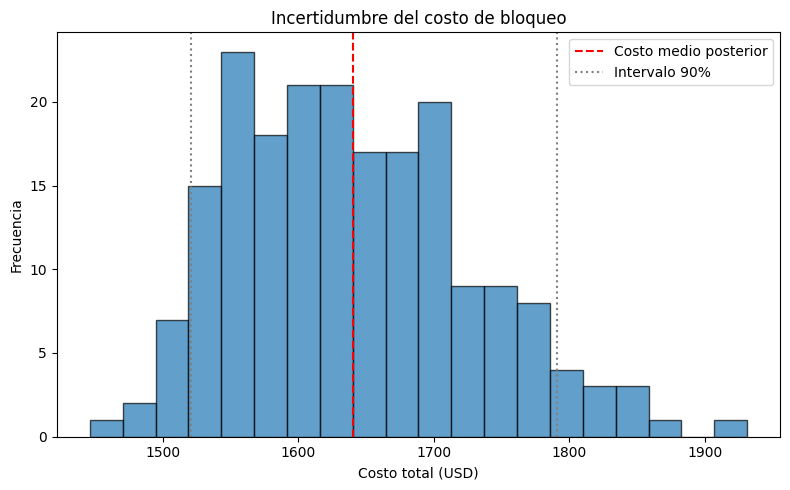

In [7]:
# ✏️ Función de costo, curva costo vs. umbral, políticas extremas y costo con 200 muestras de la posterior

# 1. Datos de prueba
y_real = np.asarray(y_test).astype(int)
montos = df.loc[X_test.index, 'monto'].to_numpy()

# Probabilidades bayesianas de la Parte 2
p_bayes = np.asarray(prob_bayes)

# 2. Funcion de costo
def costo_total(probabilidades, umbral):
    bloquear = probabilidades >= umbral

    costo_fraude = np.sum(
        (~bloquear) * (y_real == 1) * montos
    )

    costo_bloqueo = np.sum(
        bloquear * (y_real == 0) * 5
    )

    return float(costo_fraude + costo_bloqueo)

# 3. Evaluar umbrales entre 0.02 y 0.90
umbrales = np.round(
    np.arange(0.02, 0.901, 0.01), 2
)

costos = np.array([
    costo_total(p_bayes, u)
    for u in umbrales
])

tabla_costos = pd.DataFrame({
    'umbral': umbrales,
    'costo_total_usd': costos
})

pos_optima = np.argmin(costos)
umbral_optimo = float(umbrales[pos_optima])
costo_optimo = float(costos[pos_optima])

print("UMBRAL OPTIMO:", umbral_optimo)
print("COSTO MINIMO (USD):", round(costo_optimo, 2))

# 4. Politicas extremas
costo_no_bloquear = float(
    np.sum(y_real * montos)
)

costo_bloquear_todo = float(
    np.sum((y_real == 0) * 5)
)

ahorro = costo_no_bloquear - costo_optimo

comparacion = pd.DataFrame({
    'Politica': [
        'No bloquear nada',
        'Bloquear todo',
        'Umbral optimo'
    ],
    'Costo USD': [
        costo_no_bloquear,
        costo_bloquear_todo,
        costo_optimo
    ]
})

print("\nCOMPARACION DE POLITICAS")
display(comparacion.round(2))

print("\nAHORRO FRENTE A NO BLOQUEAR")
print("USD:", round(ahorro, 2))

# 5. Grafico de costo por umbral
plt.figure(figsize=(9, 5))

plt.plot(
    umbrales,
    costos,
    linewidth=2,
    label='Costo total'
)

plt.axvline(
    umbral_optimo,
    linestyle='--',
    color='red',
    label=f'Optimo: {umbral_optimo:.2f}'
)

plt.scatter(
    [umbral_optimo],
    [costo_optimo],
    color='red',
    zorder=3
)

plt.xlabel('Umbral de bloqueo')
plt.ylabel('Costo total (USD)')
plt.title('Costo total segun umbral de bloqueo')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 6. Incertidumbre con 200 muestras posteriores
a_post = tr_bayes.posterior['a'].values.reshape(-1)

b_post = tr_bayes.posterior['b'].values.reshape(
    -1, len(variables)
)

rng = np.random.default_rng(42)

indices = rng.choice(
    len(a_post),
    size=200,
    replace=False
)

a_muestras = a_post[indices]
b_muestras = b_post[indices]

logits_muestras = (
    a_muestras[:, None]
    + b_muestras @ X_test_std.T
)

# Sigmoide numericamente estable
logits_muestras = np.clip(
    logits_muestras, -500, 500
)

prob_muestras = 1 / (
    1 + np.exp(-logits_muestras)
)

costos_posteriores = np.array([
    costo_total(prob, umbral_optimo)
    for prob in prob_muestras
])

# 7. Resumen de incertidumbre
costo_medio = costos_posteriores.mean()

ic_inferior, ic_superior = np.percentile(
    costos_posteriores, [5, 95]
)

resumen_costos = pd.DataFrame({
    'Indicador': [
        'Umbral optimo',
        'Costo con probabilidad media',
        'Costo medio posterior',
        'Limite inferior 90%',
        'Limite superior 90%',
        'Ahorro frente a no bloquear'
    ],
    'Valor': [
        umbral_optimo,
        costo_optimo,
        costo_medio,
        ic_inferior,
        ic_superior,
        ahorro
    ]
})

print("\nRESULTADOS CON INCERTIDUMBRE")
display(resumen_costos.round(2))

# 8. Distribucion de costos posteriores
plt.figure(figsize=(8, 5))

plt.hist(
    costos_posteriores,
    bins=20,
    edgecolor='black',
    alpha=0.7
)

plt.axvline(
    costo_medio,
    color='red',
    linestyle='--',
    label='Costo medio posterior'
)

plt.axvline(
    ic_inferior,
    color='gray',
    linestyle=':'
)

plt.axvline(
    ic_superior,
    color='gray',
    linestyle=':',
    label='Intervalo 90%'
)

plt.xlabel('Costo total (USD)')
plt.ylabel('Frecuencia')
plt.title('Incertidumbre del costo de bloqueo')
plt.legend()
plt.tight_layout()
plt.show()

**✍️ Respuesta:** La evaluación de costos identificó un umbral óptimo de bloqueo del 7%, con un costo total de USD 1555.92. Este resultado es considerablemente inferior al costo de no bloquear ninguna transacción (USD 13454.94) y al de bloquearlas todas (USD 4065). El ahorro estimado frente a no bloquear alcanza USD 11899.02, equivalente al 88.4%.

Al incorporar 200 muestras posteriores, el costo medio aumentó a USD 1640.02, con un intervalo empírico del 90% entre USD 1520.61 y USD 1791.31, evidenciando incertidumbre en los resultados.

En consecuencia, el bloqueo basado en probabilidades permite equilibrar las pérdidas por fraude y los costos de bloquear operaciones legítimas. No obstante, el umbral del 7% fue optimizado sobre la muestra de prueba, por lo que debería validarse con nuevos datos antes de aplicarse operativamente.

---
## Parte 5 · Informe ejecutivo (20 pts)
Para el **comité de riesgos** de PagoYa. Entre media y una página. Sin código: cifras de **sus** resultados.

### 1. Hallazgos
El análisis identificó que las variables con mayor asociación positiva con el fraude son el uso de un dispositivo nuevo (OR = 2.52) y el ratio de la transacción (OR = 2.22). El modelo bayesiano presentó una convergencia adecuada, sin divergencias.

En la comparación predictiva, XGBoost obtuvo una mayor capacidad de discriminación (AUC = 0.9277 frente a 0.8943), mientras que el modelo bayesiano presentó un menor error probabilístico (Brier score de 0.0550 frente a 0.0616) y una calibración por deciles generalmente más favorable.

El análisis jerárquico mostró diferencias provinciales moderadas y un efecto de contracción hacia el nivel general. Tungurahua presentó el mayor ajuste, pasando de una tasa observada de 13.92% a una estimación de 10.72%, frente a una tasa nacional de 9.51%.

### 2. Recomendación
Se recomienda utilizar inicialmente el modelo bayesiano para establecer decisiones de bloqueo basadas en probabilidades, y XGBoost como herramienta complementaria para priorizar transacciones de mayor riesgo.

El umbral que minimizó los costos en la muestra analizada fue del 7%, con un costo de USD 1555.92 y un ahorro de USD 11899.02 (88.4%) frente a no bloquear ninguna transacción. Al incorporar la incertidumbre posterior, el costo medio fue de USD 1640.02, con un intervalo empírico del 90% entre USD 1520.61 y USD 1791.31.

Se propone validar este umbral con nuevos datos antes de implementarlo en producción.

### 3. Limitaciones y riesgos
Los resultados provienen de datos simulados, por lo que no necesariamente representan el comportamiento real del fraude. Además, podrían existir variables relevantes no consideradas, como el historial transaccional y los patrones de comportamiento del cliente.

La variable hora fue incorporada linealmente, aunque su relación con el fraude podría ser cíclica y no lineal, especialmente durante la madrugada. Asimismo, los patrones de fraude pueden cambiar con el tiempo y afectar el desempeño predictivo.

Por ello, se recomienda realizar validaciones temporales, monitorear periódicamente la discriminación, la calibración y los costos, y actualizar los modelos y umbrales cuando sea necesario.
